In [28]:
import math
import numpy as np
import scipy
import matplotlib.pyplot as plt
import openfermion as of
from openfermionpyscf import run_pyscf

This technique is taken from https://quantum-journal.org/papers/q-2025-04-01-1682/

In [29]:
ENERGY_ERR = 1.6e-3 # chemical accuracy in Ha

In [30]:
def thm4_M_formula(D, eta, eps, tau, theta):
    """Eq. (28): M = ceil( 2 [ (2.07/pi (ln 4D + gamma) + 1) / (eta - 2 eps) ]^2 [ ln ln(1/(tau eps)) + ln(1/theta) ] ).
    All logs are natural; gamma is the Euler-Mascheroni constant (additive, from H_D ~ ln D + gamma)."""
    assert eta > 2 * eps

    factor1_num = 2.07 / np.pi * (np.log(4 * D) + np.euler_gamma) + 1
    factor1_denom = eta - 2 * eps
    factor2 = np.log(np.log(1. / (tau * eps))) + np.log(1. / theta)
    return np.ceil(2 * (factor1_num / factor1_denom) ** 2 * factor2)

In [31]:
def W0(z):
    """Principal-branch Lambert W. scipy returns complex dtype even for real results, so take the real part."""
    w = scipy.special.lambertw(z, k=0)
    assert abs(w.imag) < 1e-12, f"W0({z}) is not real"
    return w.real


def eq7_beta(delta, eps):
    """Eq. (7): beta = max(1, W0(2/(pi eps^2)) / (4 sin^2 delta))."""
    return max(1., W0(2. / (np.pi * eps ** 2)) / (4 * np.sin(delta) ** 2))


def f_thm3(beta, x):
    """Eq. (26): f(beta, x) = -(ln x + beta) / W0(-[1 + ln(x)/beta] e^{-1}).
    The paper names the second argument eps, but it is a dummy variable; in Eq. (25) it is evaluated at
    x = min(1, 4 e^{-w(eps)/2}), NOT at the theorem's input eps."""
    return -(np.log(x) + beta) / W0(-(1 + np.log(x) / beta) * np.exp(-1))


def thm3_D_formula(delta, eps):
    """Eq. (25): D = 2 ceil( sqrt( f(beta, min(1, 4 e^{-w/2})) w ) ) + 1, with w = W0(18/(pi eps^2))."""
    beta = eq7_beta(delta, eps)
    w_eps = W0(18. / (np.pi * eps ** 2))
    x = min(1., 4. * np.exp(-w_eps / 2))
    return 2 * np.ceil(np.sqrt(f_thm3(beta, x) * w_eps)) + 1

In [32]:
def shot_count(energy_err, eta, ham_norm, theta=0.1, tau_safety=0.99):
    # theta is the failure probability (success probability 1 - theta).
    # Eq. (1): tau ||H|| < pi/2 (strict), so back off from the boundary by tau_safety.
    # delta is the precision in the rescaled (tau H) units, and the paper
    # relates the two via eps = delta / tau (Sec. 2; restated as delta = tau eps in the proof of Thm 4).
    tau = tau_safety * np.pi / (2. * ham_norm)
    eps = energy_err
    delta = tau * eps
    D = thm3_D_formula(delta, eps)
    return thm4_M_formula(D, eta, eps, tau, theta)

In [33]:
def hydrogen_chain_ham_norm(natoms, bond_distance=1.0):
    """Spectral norm of the JW-mapped H_n chain Hamiltonian (sto-3g)."""
    geometry = [("H", (0, 0, i * bond_distance)) for i in range(natoms)]
    molecule = of.MolecularData(geometry, basis="sto-3g", multiplicity=1, charge=natoms % 2)
    molecule = run_pyscf(molecule, run_scf=True, run_mp2=True, verbose=False)

    hamiltonian = of.jordan_wigner(of.get_fermion_operator(molecule.get_molecular_hamiltonian()))
    hamiltonian_matrix = of.linalg.get_sparse_operator(hamiltonian)
    # Spectral norm (largest |eigenvalue|), not the Frobenius norm that scipy.sparse.linalg.norm returns.
    return abs(scipy.sparse.linalg.eigsh(hamiltonian_matrix, k=1, which="LM", return_eigenvectors=False)[0])

In [34]:
natoms_list = [3, 4, 5, 6, 7]
ham_norms = {n: hydrogen_chain_ham_norm(n) for n in natoms_list}
for n, norm in ham_norms.items():
    print(f"H{n}: ||H|| = {norm:.4f} Ha")

H3: ||H|| = 1.5781 Ha
H4: ||H|| = 2.8706 Ha
H5: ||H|| = 4.3059 Ha
H6: ||H|| = 5.8511 Ha
H7: ||H|| = 7.4864 Ha


In [35]:
etas = np.linspace(0.5, 0.999, num=50)
shot_counts = {
    n: np.array([shot_count(ENERGY_ERR, eta, ham_norms[n]) for eta in etas])
    for n in natoms_list
}

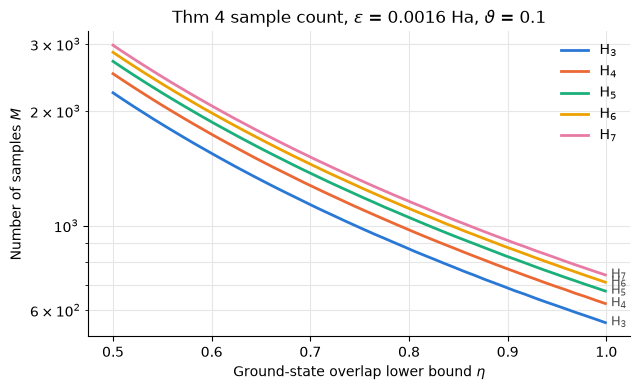

In [36]:
colors = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]  # fixed categorical order

fig, ax = plt.subplots(figsize=(6.5, 4))
for n, color in zip(natoms_list, colors):
    ax.plot(etas, shot_counts[n], color=color, linewidth=2, label=f"H$_{{{n}}}$")
    ax.annotate(f"H$_{{{n}}}$", (etas[-1], shot_counts[n][-1]), xytext=(4, 0),
                textcoords="offset points", va="center", fontsize=9, color="0.3")
ax.set_xlabel(r"Ground-state overlap lower bound $\eta$")
ax.set_ylabel("Number of samples $M$")
ax.set_title(f"Thm 4 sample count, $\\epsilon$ = {ENERGY_ERR} Ha, $\\vartheta$ = 0.1")
ax.set_yscale("log")
ax.grid(True, which="both", color="0.9", linewidth=0.8)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig("data/M_vs_eta.pdf")
plt.show()